## Stage 4: Statistical Modelling
**Research question 1:** Is delivery delay associated with low review scores
after controlling for price, freight, distance, and product category?
### Model 1: Delay only


(95346, 36)
Aşağı reytinq payı: 0.128
(95346, 36)
Aşağı reytinq payı: 0.128
Optimization terminated successfully.
         Current function value: 0.332412
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              low_score   No. Observations:                95346
Model:                          Logit   Df Residuals:                    95344
Method:                           MLE   Df Model:                            1
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.1317
Time:                        01:19:27   Log-Likelihood:                -31694.
converged:                       True   LL-Null:                       -36501.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -2.

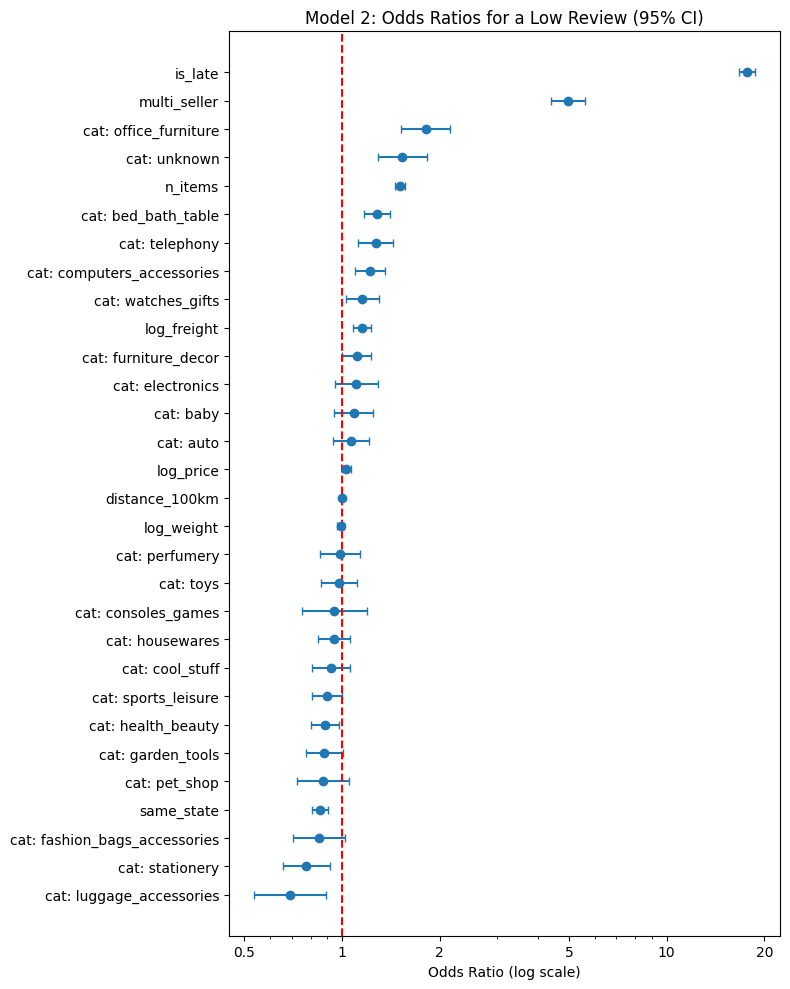

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
df = pd.read_csv('olist_model_data.csv')

model_df = df.dropna(subset=['review_score', 'distance_km']).copy()
model_df['low_score'] = (model_df['review_score'] <= 2).astype(int)

print(model_df.shape)
print('Aşağı reytinq payı:', model_df['low_score'].mean().round(3))
df = pd.read_csv('olist_model_data.csv')

model_df = df.dropna(subset=['review_score', 'distance_km']).copy()
model_df['low_score'] = (model_df['review_score'] <= 2).astype(int)

print(model_df.shape)
print('Aşağı reytinq payı:', model_df['low_score'].mean().round(3))
m1 = smf.logit('low_score ~ is_late', data=model_df).fit()
print(m1.summary())
or_table = pd.DataFrame({
    'odds_ratio': np.exp(m1.params),
    'ci_low': np.exp(m1.conf_int()[0]),
    'ci_high': np.exp(m1.conf_int()[1])
})
or_table.round(2)
### Model 2: Delay + controls
model_df['distance_100km'] = model_df['distance_km'] / 100
model_df['multi_seller'] = (model_df['n_sellers'] > 1).astype(int)

formula = (
    'low_score ~ is_late + log_price + log_freight + log_weight'
    ' + distance_100km + n_items + multi_seller + same_state'
    ' + C(category_grouped, Treatment("other"))'
)

m2 = smf.logit(formula, data=model_df).fit()
print(m2.summary())
def get_or_table(model):
    return pd.DataFrame({
        'odds_ratio': np.exp(model.params),
        'ci_low': np.exp(model.conf_int()[0]),
        'ci_high': np.exp(model.conf_int()[1]),
        'p_value': model.pvalues
    }).round(3)

get_or_table(m2)
import os

ors = get_or_table(m2).drop('Intercept')

ors.index = (ors.index
    .str.replace('C(category_grouped, Treatment("other"))[T.', 'cat: ', regex=False)
    .str.replace('[T.True', '', regex=False)
    .str.replace(']', '', regex=False))

ors = ors.sort_values('odds_ratio')

plt.figure(figsize=(8, 10))
plt.errorbar(ors['odds_ratio'], ors.index,
             xerr=[ors['odds_ratio'] - ors['ci_low'], ors['ci_high'] - ors['odds_ratio']],
             fmt='o', capsize=3)
plt.axvline(1, color='red', linestyle='--')
plt.xscale('log')
plt.xticks([0.5, 1, 2, 5, 10, 20], ['0.5', '1', '2', '5', '10', '20'])
plt.xlabel('Odds Ratio (log scale)')
plt.title('Model 2: Odds Ratios for a Low Review (95% CI)')
plt.tight_layout()

os.makedirs('figures', exist_ok=True)
plt.savefig('figures/forest_plot_model2.png', dpi=150, bbox_inches='tight')

plt.show()



### Key findings: Model 2
- Late delivery remains the strongest predictor of a low review after controls
  (OR = 17.7, 95% CI 16.7–18.7; Model 1: 16.3). Its effect is not explained by
  price, freight, distance or category.
- Orders with multiple sellers have ~5× higher odds of a low review,
  likely because items arrive separately.
- Distance has no significant effect once delay is controlled for (p = 0.45),
  consistent with distance affecting satisfaction mainly through delay.
- Office furniture has 1.8× higher odds of a low review than the "other" category.
- Note: odds ratios overstate risk ratios when the outcome is common
  (late vs on-time: OR ≈ 16, risk ratio ≈ 7).
- Pseudo R² rises only from 0.13 to 0.165: delay is the main driver.
